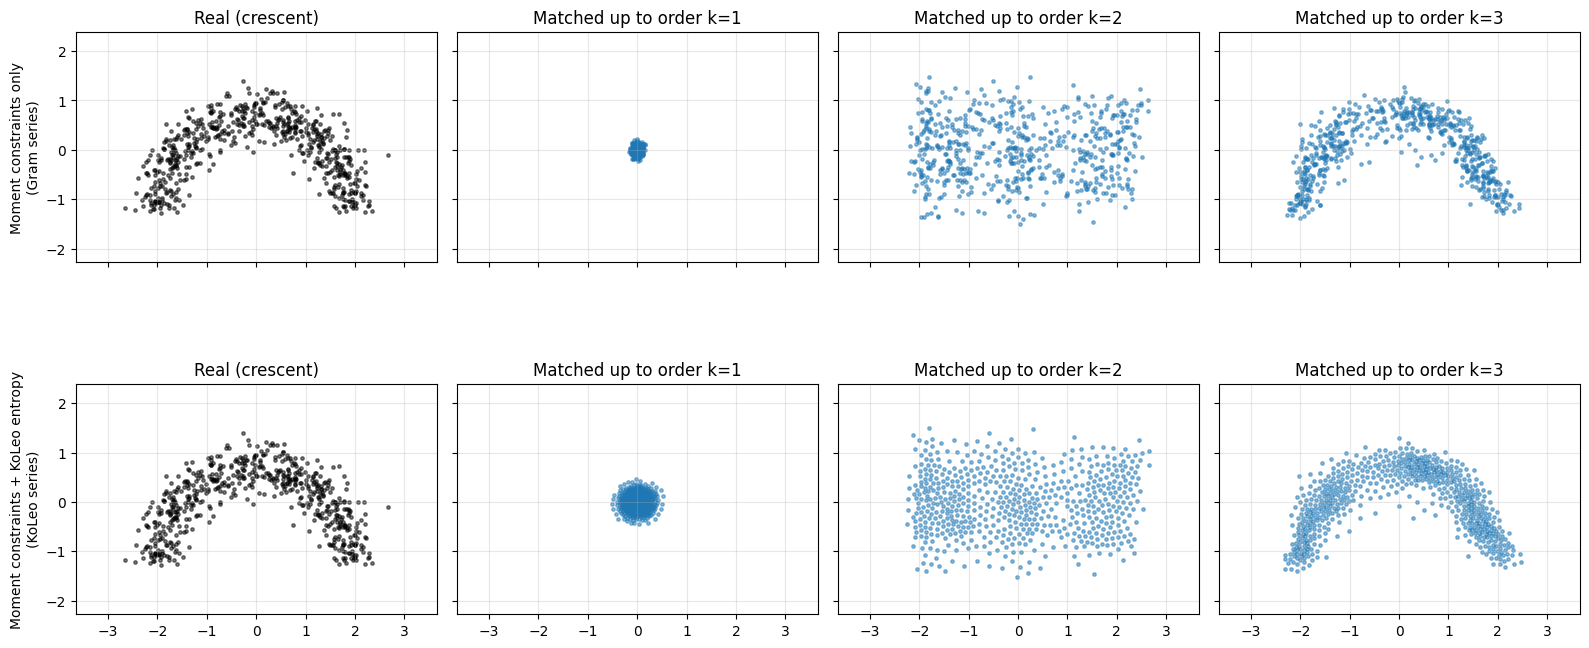

normalized moment error ||T_k^fake - T_k^real||^2 / mean||r||^(2k)  (k=1..4)
gram  k=1: 1.3e-10  4.8e-01  5.0e-02  2.5e-01   koleo=-5.439
gram  k=2: 9.7e-11  0.0e+00  7.2e-02  1.7e-03   koleo=-2.821
gram  k=3: 2.3e-10  2.9e-08  0.0e+00  6.9e-04   koleo=-3.185
koleo k=1: 1.1e-10  4.6e-01  5.0e-02  2.5e-01   koleo=-3.551
koleo k=2: 1.3e-10  0.0e+00  7.1e-02  1.8e-03   koleo=-2.041
koleo k=3: -4.0e-10  0.0e+00  -3.3e-09  4.0e-04   koleo=-2.354
real koleo=-3.124


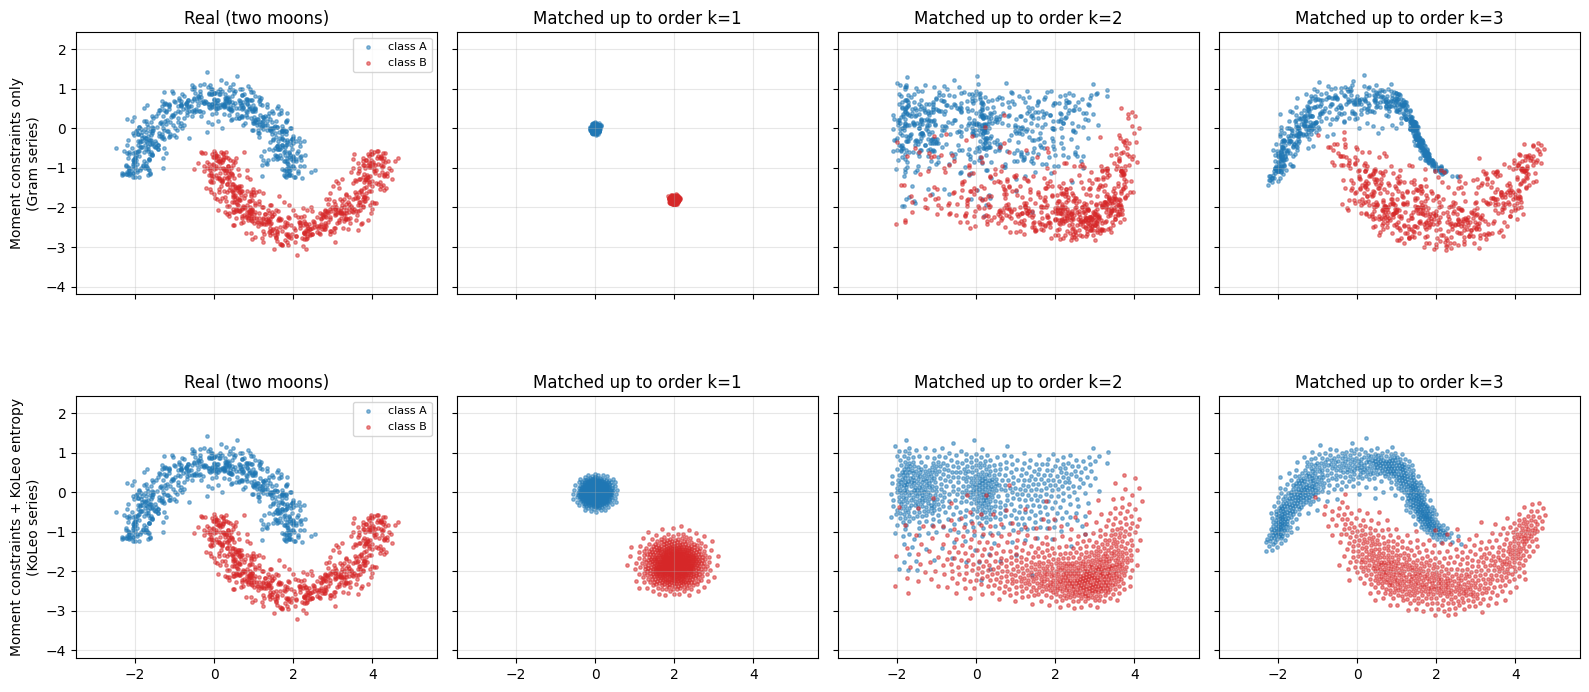

In [ ]:
# %% [markdown]
# # モーメント編集(deletion)デモ: 何次まで合わせると元分布にどこまで近づくか
#
# CIFAR-10実験(gram_k1/k2/k3 と koleo 系列)の縮図を2次元で可視化する。
# - real: 三日月分布(上下非対称 → 3次モーメントが非自明)
# - k=1 / k=2 / k=3: その次数までのモーメントテンソルを real に一致させる
# - 上段: モーメント制約のみ(Gram系列)、下段: + KoLeo エントロピー最大化(KoLeo系列)
#
# k次モーメントの Frobenius 内積は Gram trick <T^A,T^B> = sum((A@B.T)**k)/(n_A n_B)。
# 初期値は「潰れた塊」。ガウスから始めると制約の有無で差が出ないため。
# Colab にそのまま貼り付け可。GPU不要(1条件あたり CPU 1コアで30〜60秒)。

# %%
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)


# %% [markdown]
# ## 1. 元分布(三日月)

# %%
def make_crescent(n, seed=0, radius=2.0, noise=0.25):
    """上半分の円弧に沿った三日月分布。左右対称・上下非対称なので歪度が非ゼロ。"""
    rng = np.random.default_rng(seed)
    theta = rng.uniform(0.0, np.pi, n)
    r = rng.normal(radius, noise, n)
    x = np.stack([r * np.cos(theta), r * np.sin(theta)], axis=1)
    x -= x.mean(axis=0)
    return x.astype(np.float32)


# %% [markdown]
# ## 2. Gram trick によるモーメント損失と編集アルゴリズム

# %%
def gram_inner(A, B, k):
    """<T_k^A, T_k^B> = (1/(n_A n_B)) sum_{ij} (a_i . b_j)^k"""
    return ((A @ B.t()) ** k).sum() / (A.shape[0] * B.shape[0])


def koleo(x):
    """Kozachenko-Leonenko エントロピー推定量(最近傍距離の対数平均)。"""
    return torch.cdist(x, x).kthvalue(2).values.log().mean()


def edit_distribution(
    real, max_order, use_entropy, box_low, box_high,
    n_steps=2000, lr=0.05, koleo_weight=0.010008,
    init_std=0.05, init_offset=(1.0, -1.0), seed=42,
):
    """
    1..max_order 次のモーメントテンソルを real に一致させる。
    use_entropy=True なら KoLeo エントロピーも同時に最大化する。
    box制約は sigmoid reparametrization。初期値は潰れた塊。
    """
    g = torch.Generator().manual_seed(seed)
    real = torch.as_tensor(real, dtype=torch.float32)
    n, d = real.shape

    low = torch.as_tensor(box_low, dtype=torch.float32)
    high = torch.as_tensor(box_high, dtype=torch.float32)
    span = high - low
    eps = 1e-6

    # real 側の自己内積(定数)と正規化スケール。
    # scale_k = mean_i ||r_i||^(2k) は ||T_k||^2 の自然な上界で、平均が0でも0にならない
    # (||T_k^real||^2 で割ると k=1 でゼロ割りする)
    rr = {k: gram_inner(real, real, k) for k in range(1, max_order + 1)}
    scale = {k: ((real * real).sum(1) ** k).mean() for k in range(1, max_order + 1)}

    # 低エントロピー初期値: real の平均から少しずれた位置の小さな塊
    x0 = real.mean(0) + torch.tensor(init_offset) + init_std * torch.randn(n, d, generator=g)
    u0 = torch.clamp((x0 - low) / span, eps, 1 - eps)
    z = nn.Parameter(u0.logit())
    opt = torch.optim.Adam([z], lr=lr)

    for _ in range(n_steps):
        opt.zero_grad()
        x = low + z.sigmoid() * span
        loss = 0.0
        for k in range(1, max_order + 1):
            ff = gram_inner(x, x, k)
            fr = gram_inner(x, real, k)
            loss = loss + (ff - 2 * fr + rr[k]) / scale[k]   # ||T^fake - T^real||_F^2 / scale
        if use_entropy:
            loss = loss - koleo_weight * koleo(x)
        loss.backward()
        opt.step()

    with torch.no_grad():
        x = low + z.sigmoid() * span
    return x.cpu().numpy()


def moment_report(x, real, max_order=4):
    """何次までどれだけ合っているかを正規化誤差で返す。"""
    x = torch.as_tensor(x, dtype=torch.float32)
    real = torch.as_tensor(real, dtype=torch.float32)
    out = []
    for k in range(1, max_order + 1):
        rr = gram_inner(real, real, k)
        scale = ((real * real).sum(1) ** k).mean()
        out.append(((gram_inner(x, x, k) - 2 * gram_inner(x, real, k) + rr) / scale).item())
    return out


# %% [markdown]
# ## 3. 1クラス: real vs k=1 / k=2 / k=3(上段: 制約のみ、下段: + エントロピー)

# %%
n_samples = 600
real = make_crescent(n_samples, seed=1)
margin = 1.0
box_low = real.min(axis=0) - margin
box_high = real.max(axis=0) + margin

orders = [1, 2, 3]
results = {}
for use_ent in [False, True]:
    for k in orders:
        results[(use_ent, k)] = edit_distribution(
            real, max_order=k, use_entropy=use_ent, box_low=box_low, box_high=box_high,
        )

row_labels = ["Moment constraints only\n(Gram series)",
              "Moment constraints + KoLeo entropy\n(KoLeo series)"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
for r, use_ent in enumerate([False, True]):
    axes[r, 0].scatter(real[:, 0], real[:, 1], s=6, alpha=0.5, color="k")
    axes[r, 0].set_title("Real (crescent)")
    axes[r, 0].set_ylabel(row_labels[r])
    for c, k in enumerate(orders, start=1):
        x = results[(use_ent, k)]
        axes[r, c].scatter(x[:, 0], x[:, 1], s=6, alpha=0.5, color="tab:blue")
        axes[r, c].set_title(f"Matched up to order k={k}")
for ax in axes.flat:
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_xlim(box_low[0], box_high[0])
    ax.set_ylim(box_low[1], box_high[1])
plt.tight_layout()
plt.savefig("moment_editing_demo_orders.png", dpi=150)
plt.show()

print("normalized moment error ||T_k^fake - T_k^real||^2 / mean||r||^(2k)  (k=1..4)")
for use_ent in [False, True]:
    for k in orders:
        errs = moment_report(results[(use_ent, k)], real, max_order=4)
        tag = "koleo" if use_ent else "gram "
        print(f"{tag} k={k}: " + "  ".join(f"{e:.1e}" for e in errs)
              + f"   koleo={koleo(torch.as_tensor(results[(use_ent, k)])).item():.3f}")
print(f"real koleo={koleo(torch.as_tensor(real)).item():.3f}")


# %% [markdown]
# ## 4. 2クラス版: 上下逆向きの三日月(two moons)

# %%
real_a = make_crescent(n_samples, seed=10)
real_b = -make_crescent(n_samples, seed=20) + np.array([2.0, -1.8], dtype=np.float32)
#real_b = -make_crescent(n_samples, seed=20) + np.array([1.0, 0.5], dtype=np.float32)

box_low2 = np.minimum(real_a.min(0), real_b.min(0)) - margin
box_high2 = np.maximum(real_a.max(0), real_b.max(0)) + margin

results2 = {}
for use_ent in [False, True]:
    for k in orders:
        ea = edit_distribution(real_a, k, use_ent, box_low2, box_high2, seed=42)
        eb = edit_distribution(real_b, k, use_ent, box_low2, box_high2, seed=43,
                               init_offset=(-1.0, 1.0))
        results2[(use_ent, k)] = (ea, eb)

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
for r, use_ent in enumerate([False, True]):
    axes[r, 0].scatter(real_a[:, 0], real_a[:, 1], s=6, alpha=0.5, color="tab:blue", label="class A")
    axes[r, 0].scatter(real_b[:, 0], real_b[:, 1], s=6, alpha=0.5, color="tab:red", label="class B")
    axes[r, 0].set_title("Real (two moons)")
    axes[r, 0].set_ylabel(row_labels[r])
    axes[r, 0].legend(fontsize=8)
    for c, k in enumerate(orders, start=1):
        ea, eb = results2[(use_ent, k)]
        axes[r, c].scatter(ea[:, 0], ea[:, 1], s=6, alpha=0.5, color="tab:blue")
        axes[r, c].scatter(eb[:, 0], eb[:, 1], s=6, alpha=0.5, color="tab:red")
        axes[r, c].set_title(f"Matched up to order k={k}")
for ax in axes.flat:
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.set_xlim(box_low2[0], box_high2[0])
    ax.set_ylim(box_low2[1], box_high2[1])
plt.tight_layout()
plt.savefig("moment_editing_demo_orders_two_classes.png", dpi=150)
plt.show()